# Guía demostrativa · Imágenes reales para analizar cultivo y malezas

Seguimos un caso real para ver cómo se trabaja con una imagen multiespectral de dron: reconocemos las bandas, observamos una composición visual, calculamos índices y los contrastamos con etiquetas de referencia. El recorrido muestra cómo una señal puede ayudar a ubicar zonas para revisar y por qué un índice aislado no alcanza para identificar una maleza.

Las celdas de código ejecutan cada etapa y muestran sus resultados. El umbral se usa solo como ejemplo visual; el notebook no produce un detector validado ni una recomendación agronómica.

## El caso y la fuente de las imágenes

Usaremos **WeedsGalore**, un conjunto abierto de imágenes reales de un campo de maíz en Marquardt, Alemania. Un dron registró imágenes multiespectrales durante cuatro fechas de 2023. Cada recorte anotado mide 600 × 600 píxeles; el muestreo en terreno es de aproximadamente **2,5 mm por píxel**. Las etiquetas de referencia fueron revisadas por personas y diferencian el maíz, cuatro grupos de malezas y el fondo.

La descarga del conjunto pequeño pesa aproximadamente **321 MB**. El notebook trae una sola muestra y su máscara al directorio ignorado `datos_cache/`; no incorpora el archivo grande al repositorio. Prepará la descarga antes de la clase.

- [Repositorio oficial y licencia CC BY 4.0](https://github.com/GFZ/weedsgalore)
- [Artículo de WeedsGalore (WACV 2025)](https://arxiv.org/html/2502.13103v1)
- [Descarga del conjunto de muestras](https://doidata.gfz.de/weedsgalore_e_celikkan_2024/weedsgalore-dataset.zip)

**Atribución:** Celikkan et al., *WeedsGalore: A Multispectral and Multitemporal UAV-Based Dataset for Crop and Weed Segmentation in Agricultural Maize Fields*, WACV 2025. Datos bajo licencia [Creative Commons Attribution 4.0](https://creativecommons.org/licenses/by/4.0/).

## Datos y mediciones antes de calcular

Cada recorte tiene cinco bandas alineadas: **R** (rojo), **G** (verde), **B** (azul), **RE** (*red edge*, borde rojo) y **NIR** (*near infrared*, infrarrojo cercano). El **RGB** combina rojo, verde y azul para mostrar la escena; en falso color podemos asignar NIR a uno de los canales de pantalla.

El **NDVI** (*Normalized Difference Vegetation Index*, Índice de Vegetación de Diferencia Normalizada) compara rojo y NIR:

**NDVI = (NIR − R) / (NIR + R)**

El **NDRE** (*Normalized Difference Red Edge Index*, Índice de Diferencia Normalizada del Borde Rojo) compara RE y NIR:

**NDRE = (NIR − RE) / (NIR + RE)**

NDVI puede ayudar a ubicar una respuesta compatible con vegetación; NDRE agrega otra comparación espectral. **Ninguno nombra por sí solo una planta como cultivo o maleza.** Las dos clases son vegetación y pueden tener respuestas parecidas.

En este notebook no hacemos una calibración radiométrica a reflectancia. Usamos los valores de banda del producto para aprender la manipulación y comparar una captura; por eso los números y el umbral son exploratorios, no trasladables a otra fecha o lote. En un trabajo operativo se documentan producto, calibración, alineación de bandas y fecha, y se valida el resultado con etiquetas y terreno. [Fórmula de NDRE en Sentinel Hub](https://custom-scripts.sentinel-hub.com/custom-scripts/planet/planetscope/ndre/).

## Carga de los datos del ejemplo

La primera ejecución descarga el archivo oficial (unos 321 MB) si todavía no está en caché. La función auxiliar selecciona una muestra anotada donde aparecen maíz y malezas, y carga sus cinco bandas junto con la máscara de referencia. En las etiquetas, `0` representa fondo, `1` cultivo y los valores mayores que `1` distintos grupos de malezas; para esta demostración agrupamos estos últimos como «malezas».

In [1]:
from pathlib import Path
import numpy as np
import sys
import matplotlib.pyplot as plt

carpeta_clase = Path.cwd()
if (carpeta_clase / "modulo_3/clase_03/datos_malezas.py").exists():
    carpeta_clase = carpeta_clase / "modulo_3/clase_03"
elif not (carpeta_clase / "datos_malezas.py").exists():
    carpeta_clase = Path("../../modulo_3/clase_03").resolve()
sys.path.insert(0, str(carpeta_clase))
from datos_malezas import cargar_muestra

bandas, etiqueta, identificador, fecha = cargar_muestra()

Muestra: 2023-06-06_0625 · fecha: 2023-06-06 · tamaño: 600 × 600 píxeles
Píxeles anotados como maíz: 24,135 · malezas: 36,982 · fondo: 298,883


## 1. Inspeccionar la imagen y las etiquetas de referencia

Primero se prepara una composición **RGB** para reconocer el lote. A su lado se muestra un **falso color**: el NIR ocupa el canal rojo de la pantalla y hace visibles diferencias que el color natural no muestra. Cambia la apariencia, pero no cambian los datos capturados.

El tercer panel superpone las etiquetas de referencia sobre el RGB: verde para maíz y rojo para malezas. Estas anotaciones sirven como comparación independiente durante el análisis; no se obtienen del índice.

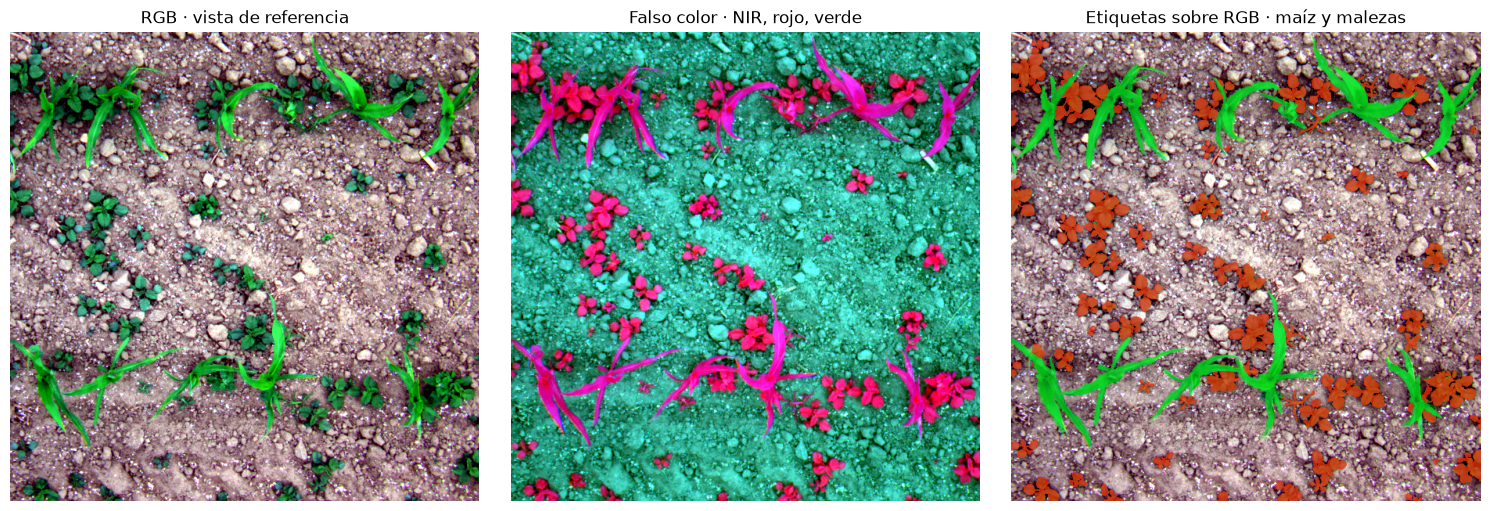

In [2]:
def estirar(banda):
    baja, alta = np.percentile(banda, (2, 98))
    return np.clip((banda - baja) / (alta - baja + 1e-6), 0, 1)

rgb = np.dstack((estirar(bandas["rojo"]), estirar(bandas["verde"]), estirar(bandas["azul"])))
falso_color = np.dstack((estirar(bandas["nir"]), estirar(bandas["rojo"]), estirar(bandas["verde"])))

referencia = np.zeros((*etiqueta.shape, 4))
referencia[etiqueta == 1] = (0.05, 0.85, 0.15, 0.62)
referencia[etiqueta > 1] = (1.00, 0.20, 0.05, 0.72)

fig, ejes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
ejes[0].imshow(rgb)
ejes[0].set_title("RGB · vista de referencia")
ejes[1].imshow(falso_color)
ejes[1].set_title("Falso color · NIR, rojo, verde")
ejes[2].imshow(rgb)
ejes[2].imshow(referencia)
ejes[2].set_title("Etiquetas sobre RGB · maíz y malezas")
for eje in ejes:
    eje.axis("off")
plt.show()

## 2. Calcular índices y ubicar zonas candidatas

NDVI y NDRE convierten dos bandas alineadas en una imagen de valores por píxel. En esta muestra, el código calcula ambos índices. Después aplicamos un umbral exploratorio de NDVI para resaltar píxeles candidatos a vegetación y los ponemos junto al mapa de referencia.

Esta selección es una primera forma de priorizar dónde mirar. Puede incluir tanto maíz como malezas y también respuestas de otros píxeles; por sí sola no asigna una especie ni valida una detección.

## Demostración: de un índice continuo a una máscara inicial

El valor fijo `0.25` permite ver cómo una regla sencilla convierte el mapa continuo de NDVI en una selección. En el resultado, los píxeles seleccionados aparecen resaltados sobre la escena. El umbral es únicamente ilustrativo: no es una recomendación de uso y no se transfiere automáticamente a otra fecha o lote.

Los porcentajes impresos describen esta muestra. La coincidencia con etiquetas de planta es una observación inicial, no una métrica completa de precisión ni evidencia de que se hayan separado cultivo y malezas.

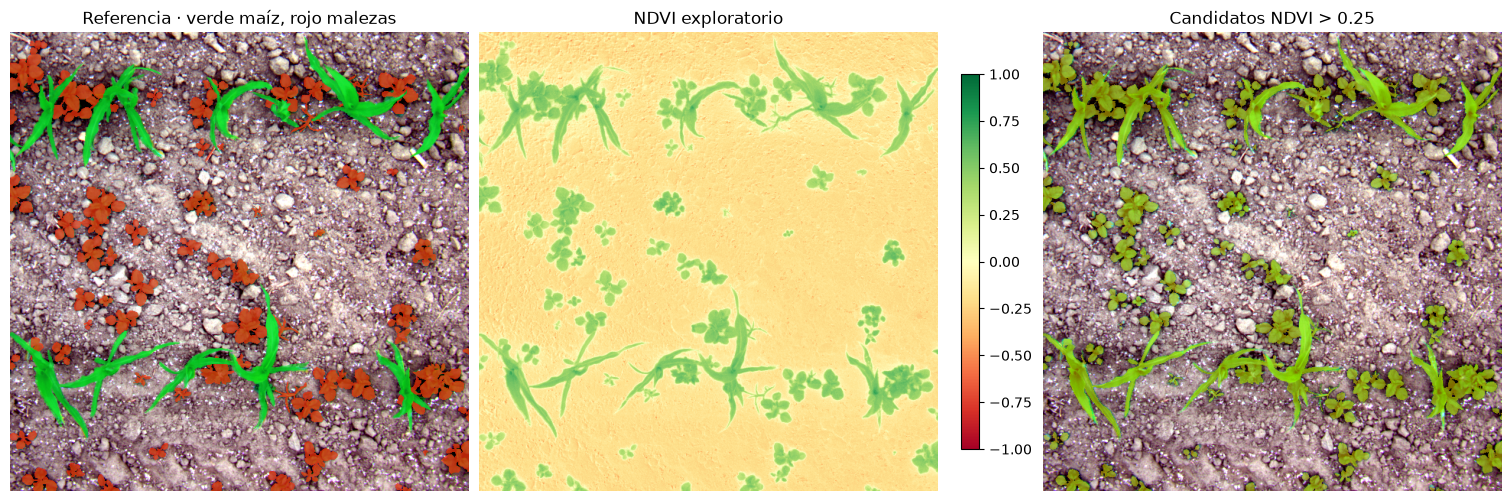

Píxeles seleccionados: 14.5% de la muestra
De esos candidatos, 96.4% coincide con una etiqueta de planta


In [3]:
rojo = bandas["rojo"]
nir = bandas["nir"]
borde_rojo = bandas["borde_rojo"]

suma_ndvi = nir + rojo
suma_ndre = nir + borde_rojo
ndvi = np.divide(nir - rojo, suma_ndvi, out=np.full_like(nir, np.nan), where=suma_ndvi != 0)
ndre = np.divide(nir - borde_rojo, suma_ndre, out=np.full_like(nir, np.nan), where=suma_ndre != 0)

umbral_ndvi = 0.25
candidatos = np.isfinite(ndvi) & (ndvi > umbral_ndvi)
porcentaje = 100 * candidatos.sum() / np.isfinite(ndvi).sum()
coinciden_con_etiqueta = 100 * np.count_nonzero(candidatos & (etiqueta > 0)) / max(candidatos.sum(), 1)

capa_candidatos = np.zeros((*etiqueta.shape, 4))
capa_candidatos[candidatos] = (1.00, 0.85, 0.00, 0.50)

fig, ejes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
ejes[0].imshow(rgb)
ejes[0].imshow(referencia)
ejes[0].set_title("Referencia · verde maíz, rojo malezas")
im = ejes[1].imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
ejes[1].set_title("NDVI exploratorio")
fig.colorbar(im, ax=ejes[1], shrink=0.78)
ejes[2].imshow(rgb)
ejes[2].imshow(capa_candidatos)
ejes[2].set_title(f"Candidatos NDVI > {umbral_ndvi:.2f}")
for eje in ejes:
    eje.axis("off")
plt.show()
print(f"Píxeles seleccionados: {porcentaje:.1f}% de la muestra")
print(f"De esos candidatos, {coinciden_con_etiqueta:.1f}% coincide con una etiqueta de planta")

## 3. Cómo se seleccionan malezas en la práctica: ejemplo en maíz

El mapa NDVI que acabamos de ver resalta **vegetación**. Para seleccionar malezas, el equipo necesita distinguir esa vegetación del cultivo y ubicarla en el lote. En un trabajo real se combinan la imagen, el diseño de siembra y ejemplos identificados por una persona que conoce el cultivo.

### Recorrido de un caso real

1. **Definir qué se quiere localizar.** Por ejemplo, ubicar parches de malezas en un lote de maíz antes de una recorrida o de una aplicación dirigida. La decisión determina qué nivel de detalle necesita el mapa.

2. **Capturar el lote desde arriba.** Se toma una imagen con un dron cuando el cultivo y las malezas ya se pueden distinguir. La resolución debe permitir reconocer las hileras y la vegetación; si el resultado se va a ubicar en el campo, la imagen se organiza como un mapa con coordenadas.

3. **Preparar las bandas.** RGB ayuda a reconocer formas y distribución. NIR y borde rojo aportan otras respuestas de la vegetación. Las bandas se alinean para que cada píxel corresponda al mismo punto del terreno. En este notebook, esas mediciones permiten construir RGB, falso color, NDVI y NDRE.

4. **Identificar ejemplos de cada clase.** Una persona revisa sectores del lote y marca qué píxeles o plantas son maíz, cuáles son malezas y cuáles son suelo. Esa anotación se convierte en una máscara de referencia. En la máscara que vimos arriba, verde representa maíz y rojo representa malezas; WeedsGalore ofrece este tipo de etiquetas para cuatro grupos de malezas.

5. **Separar cultivo y malezas.** En maíz, una pista visible es que el cultivo sigue hileras. Un método puede localizar esas hileras y marcar como candidatas las plantas que aparecen entre ellas. Otro puede aprender, a partir de las etiquetas, patrones de banda, forma y posición de cada planta. Los índices ayudan a describir la vegetación, mientras que las etiquetas y el contexto ayudan a distinguir las clases.

6. **Armar un mapa de zonas.** Los píxeles o plantas seleccionados se reúnen en sectores del lote. Así se obtiene una vista fácil de usar: dónde se concentran las malezas y qué zonas conviene revisar o tratar. En un flujo de aplicación dirigida, este resultado se convierte en un mapa de prescripción para el equipo de campo.

7. **Comprobar el resultado en el lote.** El equipo visita algunos sectores, compara lo que muestra el mapa con las plantas presentes y ajusta la selección. Después de una aplicación, puede volver a recorrer o fotografiar las zonas para revisar el resultado.

### Cómo se conecta con esta demostración

La capa amarilla de la celda anterior muestra el primer paso: **ubicar vegetación candidata**. La máscara anotada de esta muestra permite separar visualmente maíz y malezas. Los histogramas que siguen comparan NDVI y NDRE para esas etiquetas y muestran qué información aportan los índices al trabajo de clasificación.

Un estudio de maíz documenta un flujo concreto: detectar hileras, mapear la vegetación fuera de ellas, crear un mapa por zonas y usarlo para una aplicación localizada ([Sapkota et al., 2023](https://www.nature.com/articles/s41598-023-33042-0)). WeedsGalore aporta imágenes multiespectrales anotadas para segmentar maíz y grupos de malezas ([Celikkan et al., WACV 2025](https://openaccess.thecvf.com/content/WACV2025/html/Celikkan_WeedsGalore_A_Multispectral_and_Multitemporal_UAV-Based_Dataset_for_Crop_and_WACV_2025_paper.html)). Son dos ejemplos de cómo se puede pasar de una imagen a una selección práctica.

## 4. Contrastar los índices con las etiquetas

Como paso de revisión, agrupamos los píxeles anotados como maíz y como malezas y comparamos sus valores de NDVI y NDRE. Los histogramas muestran cuánto se diferencian o se superponen las respuestas de ambas clases en este recorte; las medianas resumen el centro de cada distribución.

Si los valores se superponen, un corte basado solo en ese índice confundirá parte de las clases. La forma, la ubicación entre hileras, otras bandas, más fechas y etiquetas representativas pueden aportar información adicional para un análisis posterior.

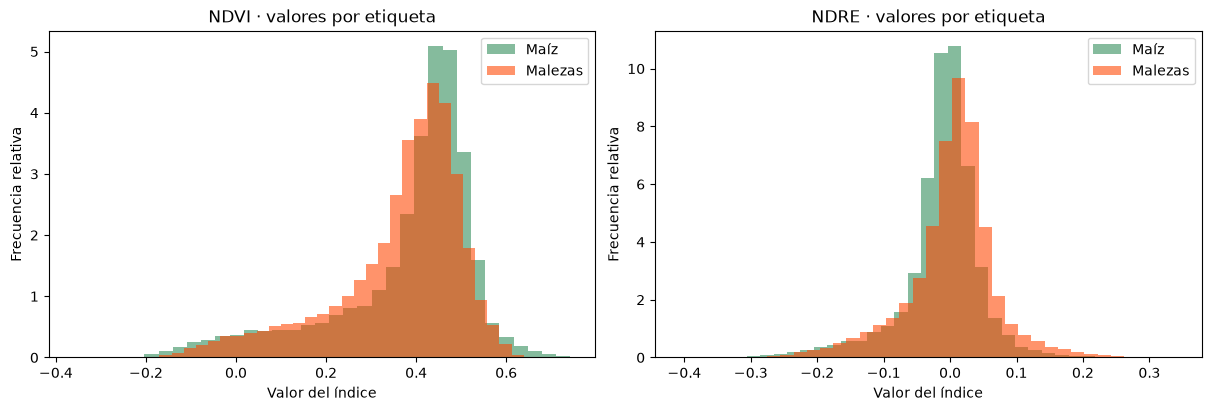

NDVI: mediana maíz = 0.431 · mediana malezas = 0.400
NDRE: mediana maíz = -0.005 · mediana malezas = 0.010


In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for eje, indice, nombre in ((ejes[0], ndvi, "NDVI"), (ejes[1], ndre, "NDRE")):
    validos = np.isfinite(indice)
    valores_maiz = indice[(etiqueta == 1) & validos]
    valores_malezas = indice[(etiqueta > 1) & validos]
    eje.hist(valores_maiz, bins=35, density=True, alpha=0.58, color="seagreen", label="Maíz")
    eje.hist(valores_malezas, bins=35, density=True, alpha=0.58, color="orangered", label="Malezas")
    eje.set_title(f"{nombre} · valores por etiqueta")
    eje.set_xlabel("Valor del índice")
    eje.set_ylabel("Frecuencia relativa")
    eje.legend()
plt.show()

for nombre, indice in (("NDVI", ndvi), ("NDRE", ndre)):
    validos = np.isfinite(indice)
    mediana_maiz = np.median(indice[(etiqueta == 1) & validos])
    mediana_malezas = np.median(indice[(etiqueta > 1) & validos])
    print(f"{nombre}: mediana maíz = {mediana_maiz:.3f} · mediana malezas = {mediana_malezas:.3f}")

## Lectura del flujo de trabajo

Este ejemplo recorre una secuencia habitual de análisis: definir qué se quiere localizar, revisar fuente y bandas, inspeccionar la imagen, generar una señal por píxel y contrastar los candidatos con referencias anotadas. El resultado de cada etapa orienta la siguiente, pero no reemplaza la validación.

- **A escala satelital**, un índice puede señalar parcelas o zonas con respuesta vegetal. Un píxel de 10 m mezcla muchas plantas y suelo, por lo que no permite ubicar una maleza individual.
- **A escala de dron**, este recorte muestra plantas por separado. NDVI y NDRE pueden aportar características para comparar clases, pero no nombran la planta por sí solos.
- **Para un uso operativo**, se revisan calibración, fecha, resolución, alineación de bandas y representatividad de las etiquetas. Luego se valida con escenas independientes y observaciones de campo antes de tomar decisiones.

Los números de esta demostración corresponden a un recorte y una captura. Otras fechas del conjunto requieren revisar calibración, etapa del cultivo y condiciones de adquisición. El ejemplo ilustra un flujo de trabajo; no valida detecciones para otros campos ni recomienda un manejo.